In [2]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from xgboost import XGBRegressor

print("Imports loaded successfully!")

Imports loaded successfully!


In [4]:
# Load dataset
data_path = os.path.join("..", "data", "salary_data.csv")
df = pd.read_csv(data_path)

print(df.describe())
print("Original shape:", df.shape)

# 1. Drop exact duplicates
df = df.drop_duplicates()

# 2. Drop rows with missing target values (Salary)
df = df.dropna(subset=['Salary'])

# 3. Remove logical outliers/impossible values (e.g., negative or zero salary/experience)
df = df[(df['Salary'] > 0) & (df['Years of Experience'] >= 0)]

print("Cleaned shape:", df.shape)
df.head()

               Age  Years of Experience         Salary
count  3396.000000          3396.000000    3395.000000
mean     34.837161             9.147674  134483.309867
std       8.467541             6.551151   47197.364016
min      22.000000             0.000000     350.000000
25%      28.000000             4.000000   98568.000000
50%      33.000000             8.000000  140000.000000
75%      41.000000            13.000000  180000.000000
max      62.000000            34.000000  250000.000000
Original shape: (3398, 6)
Cleaned shape: (1116, 6)


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [5]:
corr_matrix = df.corr(method='spearman', numeric_only=True)
corr_matrix

,Age,Years of Experience,Salary
Age,1.000000,0.949974,0.728438
Years of Experience,0.949974,1.000000,0.797119
Salary,0.728438,0.797119,1.000000


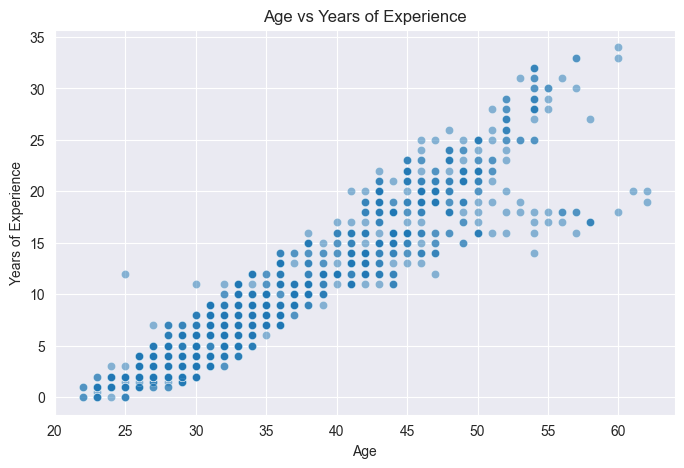

In [6]:
# Check data for  multicollinearity
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Age', y='Years of Experience', data=df, alpha=0.5)
plt.title('Age vs Years of Experience')
plt.show()

In [7]:
# Separate features
numeric_features = ['Years of Experience']
categorical_features = ['Education Level', 'Job Title']

X = df[numeric_features + categorical_features]
y = df['Salary']

# Split data for training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

Training samples: 892
Testing samples: 224


In [8]:
# Numeric pipeline: Impute missing values with median
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: Impute missing with constant string, then one-hot encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Transform the features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Set up training pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_selector', SelectKBest(score_func=f_regression, k='all')),
    ('model', XGBRegressor(random_state=42))
])

In [9]:
param_grid = {
    'model__n_estimators': [50, 100, 200],
    'model__max_depth': [None, 10, 20]
}

# Train model
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print(f"Best R² Score on Cross-Validation: {grid_search.best_score_:.4f}")
print(f"Best Parameters: {grid_search.best_params_}")

Best R² Score on Cross-Validation: 0.8721
Best Parameters: {'model__max_depth': None, 'model__n_estimators': 100}


In [10]:
best_model = grid_search.best_estimator_

# Evaluate performance
y_pred = best_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Test Set R² Score: {r2:.4f}")
print(f"Test Set RMSE: ${rmse:,.2f}")

# Save trained model
os.makedirs(os.path.join("..", "models"), exist_ok=True)
model_path = os.path.join("..", "models", "salary_pipeline.joblib")
joblib.dump(best_model, model_path)

print(f"Pipeline successfully saved to {model_path}!")

Test Set R² Score: 0.8732
Test Set RMSE: $17,426.65
Pipeline successfully saved to ..\models\salary_pipeline.joblib!
